# Chatbot LangGraph Visualization

This notebook imports the chatbot graph builder from `app/`, builds the graph with fake models, and visualizes the compiled LangGraph structure.

- No API key is required.
- No database connection is required.
- The notebook is intended for graph topology inspection only.


In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "app").exists() and (candidate / "lab").exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate project root containing app/ and lab/")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"PROJECT_ROOT: {PROJECT_ROOT}")


PROJECT_ROOT: c:\Users\SSAFY\more\more-ai\AI


In [2]:
%pip install uv langchain_core

Note: you may need to restart the kernel to use updated packages.


c:\Users\SSAFY\more\more-ai\AI\.venv\Scripts\python.exe: No module named pip


In [3]:
from IPython.display import Image, Markdown, display
from langchain_core.language_models.fake_chat_models import FakeMessagesListChatModel
from langchain_core.messages import AIMessage

from app.domain.chatbot.agents.graph import ChatbotToolBundle, build_chatbot_graph


c:\Users\SSAFY\more\more-ai\AI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
def fake_model_factory(role: str):
    return FakeMessagesListChatModel(responses=[AIMessage(content=f"{role} placeholder")])


tool_bundle = ChatbotToolBundle.empty()
chatbot_graph = build_chatbot_graph(
    model_factory=fake_model_factory,
    tools=tool_bundle,
)
compiled_graph = chatbot_graph.get_graph()

print(type(compiled_graph))


<class 'langchain_core.runnables.graph.Graph'>


In [5]:
mermaid_source = compiled_graph.draw_mermaid()
display(Markdown("## Mermaid Source"))
display(Markdown(f"```mermaid\n{mermaid_source}\n```"))


## Mermaid Source

```mermaid
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	prune_history(prune_history)
	supervisor_router(supervisor_router)
	capture_route(capture_route)
	budget_specialist(budget_specialist)
	goal_specialist(goal_specialist)
	spending_specialist(spending_specialist)
	anomaly_specialist(anomaly_specialist)
	sql_query_generator(sql_query_generator)
	capture_candidate_sql(capture_candidate_sql)
	sql_query_validator(sql_query_validator)
	capture_validator_result(capture_validator_result)
	supervisor_sql_executor(supervisor_sql_executor)
	capture_sql_result(capture_sql_result)
	capture_specialist_answer(capture_specialist_answer)
	supervisor(supervisor)
	capture_final_answer(capture_final_answer)
	__end__([<p>__end__</p>]):::last
	__start__ --> prune_history;
	anomaly_specialist --> capture_specialist_answer;
	budget_specialist --> capture_specialist_answer;
	capture_candidate_sql --> sql_query_validator;
	capture_route -. &nbsp;anomaly&nbsp; .-> anomaly_specialist;
	capture_route -. &nbsp;budget&nbsp; .-> budget_specialist;
	capture_route -. &nbsp;goal&nbsp; .-> goal_specialist;
	capture_route -. &nbsp;spending&nbsp; .-> spending_specialist;
	capture_route -. &nbsp;sql&nbsp; .-> sql_query_generator;
	capture_specialist_answer --> supervisor;
	capture_sql_result --> supervisor;
	capture_validator_result -. &nbsp;reject&nbsp; .-> supervisor;
	capture_validator_result -. &nbsp;approve&nbsp; .-> supervisor_sql_executor;
	goal_specialist --> capture_specialist_answer;
	prune_history --> supervisor_router;
	spending_specialist --> capture_specialist_answer;
	sql_query_generator --> capture_candidate_sql;
	sql_query_validator --> capture_validator_result;
	supervisor --> capture_final_answer;
	supervisor_router --> capture_route;
	supervisor_sql_executor --> capture_sql_result;
	capture_final_answer --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

```

## Rendered Graph

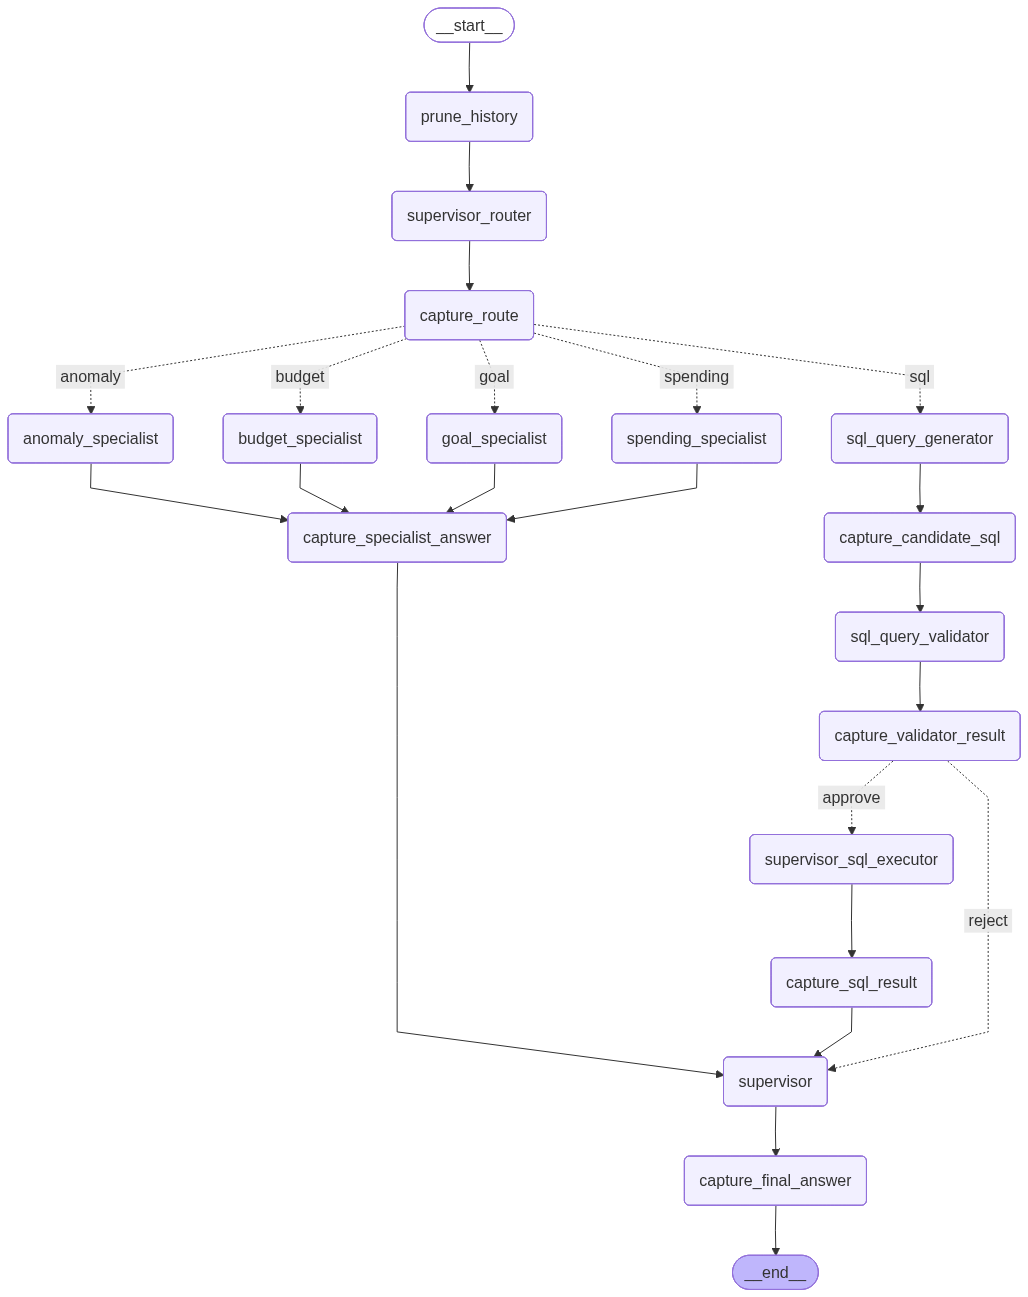

In [6]:
display(Markdown("## Rendered Graph"))
try:
    png_bytes = compiled_graph.draw_mermaid_png()
    display(Image(data=png_bytes))
except Exception as exc:
    print("PNG rendering failed, but Mermaid source is still available above.")
    print(type(exc).__name__, exc)
